## Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Ознайомлення з датасетом

Columns:  

**Years of Experience**: This column represents the number of years of work experience of each employee. The values in this column are numeric.  
**Salary**: This column represents the annual salary of each employee in US dollars.   

In [91]:
salary = pd.read_csv('salary.csv')

In [92]:
salary.head()

,Years of Experience,Salary
0,5.0,90000.0
1,3.0,65000.0
2,15.0,150000.0
3,7.0,60000.0
4,20.0,200000.0


In [93]:
salary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Years of Experience  373 non-null    float64
 1   Salary               373 non-null    float64
dtypes: float64(2)
memory usage: 6.0 KB


In [94]:
salary.dropna(inplace=True)

In [95]:
salary.info()

<class 'pandas.core.frame.DataFrame'>
Index: 373 entries, 0 to 374
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Years of Experience  373 non-null    float64
 1   Salary               373 non-null    float64
dtypes: float64(2)
memory usage: 8.7 KB


In [96]:
salary.describe()

,Years of Experience,Salary
count,373.000000,373.000000
mean,10.030831,100577.345845
std,6.557007,48240.013482
min,0.000000,350.000000
25%,4.000000,55000.000000
50%,9.000000,95000.000000
75%,15.000000,140000.000000
max,25.000000,250000.000000


<Axes: xlabel='Years of Experience', ylabel='Salary'>

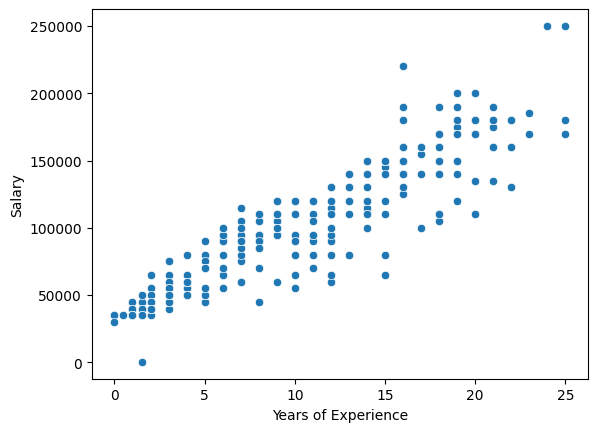

In [97]:
sns.scatterplot(x=salary['Years of Experience'], y=salary['Salary'])

## Навчання моделі

Поділ на тренувальні та тестувальні дані

In [98]:
X = salary[['Years of Experience']]

y = salary['Salary']

In [10]:
from sklearn.model_selection import train_test_split

In [99]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

Створення на навчання моделі

In [13]:
from sklearn.linear_model import LinearRegression

In [36]:
lm = LinearRegression()

In [100]:
lm.fit(X_train, y_train)

LinearRegression()

## Передбачення моделі

In [101]:
predictions = lm.predict(X_test)

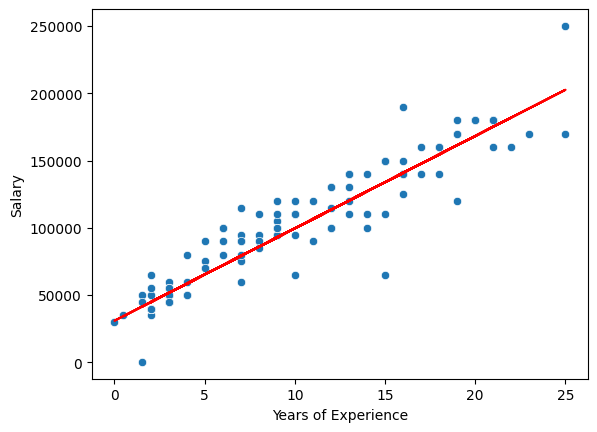

In [104]:
sns.scatterplot(x=X_test['Years of Experience'], y=y_test)
plt.plot(X_test, predictions, color='red')

## Оцінка результатів

In [80]:
from sklearn import metrics

In [105]:
print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))
print('r2_score:', metrics.r2_score(y_test, predictions))

MAE: 12709.495481839616
MSE: 292476161.7847894
RMSE: 17101.934445693252
r2_score: 0.8705110527402834
